# FoodWise: Exploratory Data Analysis for Sustainable Food Consumption

**Project Scope:** Exploratory Data Analysis (EDA) and Project Proposal for an AI solution aligned with **UN Sustainable Development Goal 12 — Responsible Consumption and Production**, specifically **Target 12.3: halving per capita global food waste by 2030**.

---

### Problem Formulation
Food waste at the household and community level frequently occurs when perishable ingredients approach their expiration dates without a clear plan for use, or when cooks lack culinary suggestions that effectively utilize items already in stock. **FoodWise** investigates whether inventory-aware, ingredient-based recipe retrieval can prevent preventable food spoilage by prioritizing expiring pantry stock.

### Critical Scope Boundary
The underlying recipe dataset (Food.com) contains historical general-purpose culinary recipes; it does **not** directly contain observed household food waste logs or operational kitchen inventory outcomes. Therefore, the scope of this notebook is strictly **Exploratory Data Analysis (EDA)**:
1. Evaluating the structural integrity, cleanliness, and quality flags of the 8,000-recipe curated sample.
2. Characterizing culinary distributions: ingredient diversity, pervasive staple items, ingredient co-occurrence patterns, category balances, serving yields, and nutritional attributes.
3. Conducting an empirical feasibility analysis of inventory-to-recipe ingredient coverage to determine whether pantry matching is viable.
4. Identifying key technical limitations and data quality issues (such as quantity/unit mismatches) to guide subsequent modeling stages.

Modeling, machine learning retrieval algorithms (e.g., TF-IDF ranking, dense semantic embeddings), and operational pilot evaluations belong to subsequent project phases.

## 1. Load paths and run provenance

The full recipe corpus is read as a stream. Only a bounded sample per source is retained in memory for plots and example inspection. Summary counts and ingredient frequencies are computed across all records.

In [1]:
from collections import Counter, defaultdict
import gzip
import json
import math
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "processed_data").exists():
    ROOT = ROOT.parent
RUN_ID = "20261022T132846Z-b7e73fc9"
RUN_DIR = ROOT / "processed_data" / "runs" / RUN_ID
MANIFEST_PATH = RUN_DIR / "run_manifest.json"
RECIPE_PATH = RUN_DIR / "recipes.jsonl.gz"
FOODKEEPER_PATH = RUN_DIR / "foodkeeper_storage_rules.jsonl"
OUTPUT_DIR = ROOT / "outputs" / "processed_eda"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
assert manifest["status"] == "completed"
assert RECIPE_PATH.is_file() and FOODKEEPER_PATH.is_file()

print("Project root:", ROOT)
print("Source run:", RUN_ID)
print("Recipe archive size (MB):", round(RECIPE_PATH.stat().st_size / 1_000_000, 1))
print("Output directory:", OUTPUT_DIR)
display(pd.DataFrame([
    {"source": source, **details}
    for source, details in manifest["sources"].items()
])[["source", "path", "size_bytes", "sha256"]])

Project root: /Users/m1/Documents/okul/samsung/Innovation Campus Assignment - Group5 - FoodWise
Source run: 20261022T132846Z-b7e73fc9
Recipe archive size (MB): 712.0
Output directory: /Users/m1/Documents/okul/samsung/Innovation Campus Assignment - Group5 - FoodWise/outputs/processed_eda


/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


,source,path,size_bytes,sha256
0,foodcom_sample,data/recipes_sample.jsonl,9468249,ffc22c2134c47e4680fb74076333edceb9be3b9d04cb4f...
1,turkish_recipes,rawdata/TR_recipes_groq_cleaned.json,8369873,5ee5870b846d84bcbb1a833ff272207dc0616dd622c858...
2,recipenlg,rawdata/RecipeNLG/RecipeNLG_dataset.csv,2294981083,f376ee0bb9f99f323761abf6270d453f4eff2002c3625d...
3,foodkeeper,rawdata/FoodKeeper-Data.xls,264704,acc2e57f2683c537a47b8c0b5d2d63501156383d564ab6...


## 2. Streaming corpus audit

Count recipes, missing/empty fields, ingredient-count distributions, and ingredient frequencies for every record without loading the 2.2-million-row archive into a DataFrame.

In [2]:
MAX_SAMPLE_PER_SOURCE = 5_000
recipe_counts = Counter()
missing_counts = defaultdict(Counter)
ingredient_count_histograms = defaultdict(Counter)
ingredient_frequencies = defaultdict(Counter)
sample_rows = defaultdict(list)
scanned = 0

with gzip.open(RECIPE_PATH, "rt", encoding="utf-8") as source:
    for line_number, line in enumerate(source, start=1):
        if not line.strip():
            continue
        recipe = json.loads(line)
        source_name = recipe.get("source", "unknown")
        recipe_counts[source_name] += 1
        scanned += 1

        ingredients = recipe.get("ingredients")
        if not isinstance(ingredients, list):
            ingredients = []
        ingredient_count_histograms[source_name][len(ingredients)] += 1
        ingredient_frequencies[source_name].update({
            ingredient for ingredient in ingredients if isinstance(ingredient, str) and ingredient
        })

        for field in ("name", "ingredients", "instructions"):
            value = recipe.get(field)
            if value is None or value == "" or value == []:
                missing_counts[source_name][field] += 1

        if len(sample_rows[source_name]) < MAX_SAMPLE_PER_SOURCE:
            sample_rows[source_name].append({
                "recipe_id": recipe.get("recipe_id"),
                "source": source_name,
                "language": recipe.get("language"),
                "name": recipe.get("name"),
                "category": recipe.get("category"),
                "servings": recipe.get("servings"),
                "preparation_minutes": recipe.get("preparation_minutes"),
                "cooking_minutes": recipe.get("cooking_minutes"),
                "difficulty": recipe.get("difficulty"),
                "cooking_methods": recipe.get("cooking_methods", []),
                "ingredients": ingredients,
                "source_ingredients": recipe.get("source_ingredients", []),
                "instructions": recipe.get("instructions", []),
                "ingredient_details": recipe.get("ingredient_details", []),
                "source_record": recipe.get("source_record", {}),
            })

assert scanned == manifest["counts"]["recipes_total"], (
    scanned, manifest["counts"]["recipes_total"]
)
print(f"Streamed and audited {scanned:,} recipes.")
print("Bounded sample size:", {source: len(rows) for source, rows in sample_rows.items()})

Streamed and audited 2,242,462 recipes.
Bounded sample size: {'foodcom_sample': 5000, 'turkish_recipes': 3320, 'recipenlg': 5000}


## 3. Dataset composition and structural quality

Missingness and ingredient counts are reported per source. These measures are descriptive; a missing instruction, for example, does not necessarily make a recipe unusable for ingredient retrieval.

,source,recipes,share_of_combined_corpus_pct,sampled_for_detail
0,foodcom_sample,8000,0.36,5000
1,recipenlg,2231142,99.50,5000
2,turkish_recipes,3320,0.15,3320


,source,field,missing_or_empty,share_pct
0,foodcom_sample,name,0,0.00
1,foodcom_sample,ingredients,0,0.00
2,foodcom_sample,instructions,0,0.00
3,recipenlg,name,0,0.00
4,recipenlg,ingredients,573,0.03
5,recipenlg,instructions,0,0.00
6,turkish_recipes,name,0,0.00
7,turkish_recipes,ingredients,0,0.00
8,turkish_recipes,instructions,0,0.00


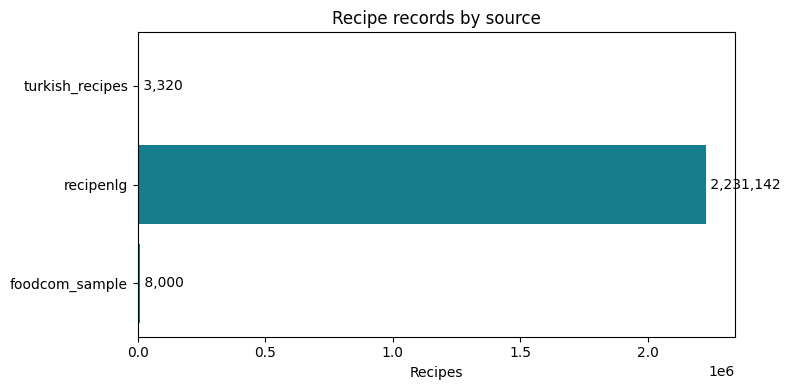

In [3]:
summary_rows = []
quality_rows = []
for source_name, count in sorted(recipe_counts.items()):
    summary_rows.append({
        "source": source_name,
        "recipes": count,
        "share_of_combined_corpus_pct": round(100 * count / scanned, 2),
        "sampled_for_detail": len(sample_rows[source_name]),
    })
    for field in ("name", "ingredients", "instructions"):
        missing = missing_counts[source_name][field]
        quality_rows.append({
            "source": source_name,
            "field": field,
            "missing_or_empty": missing,
            "share_pct": round(100 * missing / count, 2),
        })

source_summary = pd.DataFrame(summary_rows)
quality_report = pd.DataFrame(quality_rows)
display(source_summary)
display(quality_report)
source_summary.to_csv(OUTPUT_DIR / "source_summary.csv", index=False)
quality_report.to_csv(OUTPUT_DIR / "field_quality.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(source_summary["source"], source_summary["recipes"], color="#167d8d")
ax.set_title("Recipe records by source")
ax.set_xlabel("Recipes")
for y, value in enumerate(source_summary["recipes"]):
    ax.text(value, y, f" {value:,}", va="center")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "recipes_by_source.png", dpi=160)
plt.show()

## 4. Recipe and ingredient distributions

Ingredient-count distributions and most frequent terms are calculated over the full corpus. Keep language/source labels: English RecipeNLG dominates the combined count and should not be mistaken for Turkish coverage.

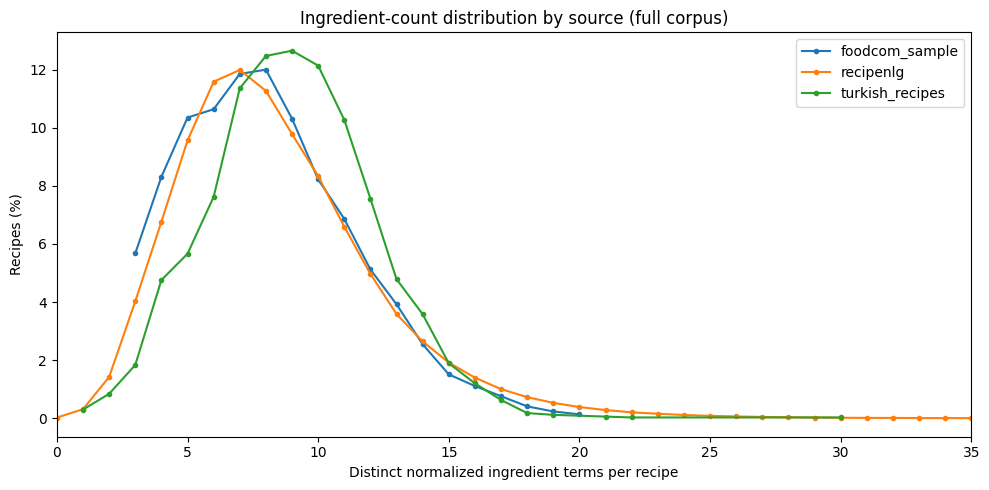

,source,rank,ingredient,recipe_document_frequency,share_of_source_recipes_pct,smooth_idf_weight
50,turkish_recipes,1,tuz,2192,66.02,1.414995
51,turkish_recipes,2,un,1330,40.06,1.914335
52,turkish_recipes,3,zeytinyağı,1227,36.96,1.994879
53,turkish_recipes,4,yumurta,988,29.76,2.211327
54,turkish_recipes,5,karabiber,928,27.95,2.273912
55,turkish_recipes,6,toz şeker,923,27.80,2.279309
56,turkish_recipes,7,süt,752,22.65,2.483956
57,turkish_recipes,8,soğan,696,20.96,2.561236
58,turkish_recipes,9,tereyağı,648,19.52,2.632589
59,turkish_recipes,10,sarımsak,645,19.43,2.637222


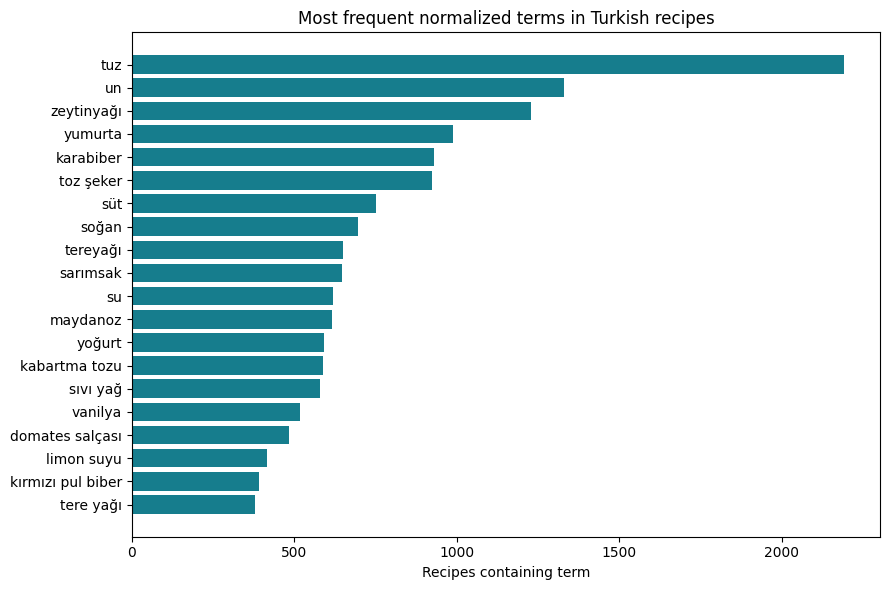

In [4]:
hist_rows = []
for source_name, histogram in sorted(ingredient_count_histograms.items()):
    total = sum(histogram.values())
    for number_of_ingredients, frequency in sorted(histogram.items()):
        hist_rows.append({
            "source": source_name,
            "ingredient_count": number_of_ingredients,
            "recipes": frequency,
            "share_pct": round(100 * frequency / total, 3),
        })
ingredient_histogram = pd.DataFrame(hist_rows)
ingredient_histogram.to_csv(OUTPUT_DIR / "ingredient_count_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
for source_name in sorted(ingredient_count_histograms):
    values = ingredient_count_histograms[source_name]
    xs = sorted(values)
    total = sum(values.values())
    ys = [100 * values[x] / total for x in xs]
    ax.plot(xs, ys, marker=".", linewidth=1.5, label=source_name)
ax.set_xlim(0, 35)
ax.set_xlabel("Distinct normalized ingredient terms per recipe")
ax.set_ylabel("Recipes (%)")
ax.set_title("Ingredient-count distribution by source (full corpus)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ingredient_count_by_source.png", dpi=160)
plt.show()

top_rows = []
for source_name, counts in sorted(ingredient_frequencies.items()):
    for rank, (ingredient, frequency) in enumerate(counts.most_common(25), start=1):
        top_rows.append({
            "source": source_name,
            "rank": rank,
            "ingredient": ingredient,
            "recipe_document_frequency": frequency,
            "share_of_source_recipes_pct": round(100 * frequency / recipe_counts[source_name], 2),
            "smooth_idf_weight": round(
                math.log((1 + recipe_counts[source_name]) / (1 + frequency)) + 1,
                6,
            ),
        })
top_ingredients = pd.DataFrame(top_rows)
top_ingredients.to_csv(OUTPUT_DIR / "top_ingredients_by_source.csv", index=False)
display(top_ingredients[top_ingredients["source"] == "turkish_recipes"].head(20))

turkish_top = top_ingredients[top_ingredients["source"] == "turkish_recipes"].head(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(turkish_top["ingredient"][::-1],
turkish_top["recipe_document_frequency"][::-1],
color="#167d8d",)
ax.set_title("Most frequent normalized terms in Turkish recipes")
ax.set_xlabel("Recipes containing term")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "top_turkish_ingredients.png", dpi=160)
plt.show()

## 5. Turkish recipe sample inspection

Review the actual source expressions, amounts, units, and instructions. The current normalizer changes casing/spacing but does not infer culinary equivalence (such as whether two related onion names should share a canonical ingredient ID).

In [5]:
turkish_df = pd.DataFrame(sample_rows.get("turkish_recipes", []))
assert not turkish_df.empty
turkish_df["ingredient_count"] = turkish_df["ingredients"].map(len)
display(turkish_df[["recipe_id", "name", "category", "servings", "ingredient_count"]].head(15))

detail = turkish_df.iloc[0]
print("Example recipe:", detail["name"])
display(pd.DataFrame(detail["ingredient_details"]))
print("First instruction steps:")
display(pd.DataFrame({"step": detail["instructions"][:5]}))

turkish_profile = pd.DataFrame([{
    "recipes_in_source": recipe_counts["turkish_recipes"],
    "recipes_with_ingredients": recipe_counts["turkish_recipes"] - missing_counts["turkish_recipes"]["ingredients"],
    "median_ingredient_count": pd.Series(
        [n for n, count in ingredient_count_histograms["turkish_recipes"].items() for _ in range(count)]
    ).median(),
    "unique_normalized_terms": len(ingredient_frequencies["turkish_recipes"]),
    "sample_size": len(turkish_df),
}])
display(turkish_profile)
turkish_profile.to_csv(OUTPUT_DIR / "turkish_recipe_profile.csv", index=False)

,recipe_id,name,category,servings,ingredient_count
0,turkish_recipes:0,Sodalı Köfte,ana yemek,NaN,10
1,turkish_recipes:1,Piliç Topkapı,ana yemek,NaN,14
2,turkish_recipes:2,Tire Şiş Köfte,ana yemek,NaN,7
3,turkish_recipes:3,Et Köfte,ana yemek,NaN,8
4,turkish_recipes:4,Şıhıl Mahşi,ana yemek,NaN,15
5,turkish_recipes:5,Tavuk Burger,ana yemek,NaN,10
6,turkish_recipes:6,Trakya Kapama,ana yemek,NaN,15
7,turkish_recipes:7,Ev Köftesi,ana yemek,NaN,11
8,turkish_recipes:8,Macar Kebabı,ana yemek,NaN,12
9,turkish_recipes:9,Sucuklu Nohut Yemeği,ana yemek,NaN,9


Example recipe: Sodalı Köfte


,name_raw,name_normalized,amount,unit
0,kıyma,kıyma,500.0,gr
1,soğan,soğan,1.0,adet
2,galeta unu,galeta unu,0.5,çay bardağı
3,tuz,tuz,1.0,tatlı kaşığı
4,kırmızı toz biber,kırmızı toz biber,1.0,çay kaşığı
5,kırmızı pul biber,kırmızı pul biber,1.0,çay kaşığı
6,kimyon,kimyon,1.0,çay kaşığı
7,karabiber,karabiber,0.5,çay kaşığı
8,kabartma tozu,kabartma tozu,0.5,paket
9,soda,soda,1.0,çay bardağı


First instruction steps:


,step
0,Derin bir kap içine 1 adet büyük boy soğan ren...
1,Rendelediğiniz soğanın suyu varsa suyunu süzün.
2,Ardından üzerine yarım kilo kıyma koyun.
3,"Daha sonra kaba yarım çay bardağı galeta unu, ..."
4,Son olarak köfteli harcın üzerine 1 çay bardağ...


,recipes_in_source,recipes_with_ingredients,median_ingredient_count,unique_normalized_terms,sample_size
0,3320,3320,9.0,1276,3320


## 6. Turkish ingredient and recipe quality audit

This additional EDA checks exact duplicate titles/ingredient signatures, screens ingredient-set near-duplicates at Jaccard similarity ≥ 0.80, and reports category-specific ingredient frequencies. Near-duplicate pairs and raw-name variants are review candidates only; similarity does not establish duplicate recipes or culinary synonymy.

In [6]:
turkish_df["normalized_title"] = turkish_df["name"].map(
    lambda value: " ".join(unicodedata.normalize("NFKC", str(value)).casefold().split())
)
turkish_df["ingredient_signature"] = turkish_df["ingredients"].map(
    lambda values: tuple(sorted(set(values)))
)

duplicate_rows = []
for field, label in (
    ("normalized_title", "normalized_title"),
    ("ingredient_signature", "ingredient_set"),
):
    counts = turkish_df[field].value_counts()
    duplicate_rows.append({
        "check": label,
        "groups_with_more_than_one_recipe": int(counts.gt(1).sum()),
        "recipes_in_repeated_groups": int(counts[counts.gt(1)].sum()),
        "excess_records_after_one_per_group": int((counts[counts.gt(1)] - 1).sum()),
    })

combined_signature_counts = turkish_df.groupby(
    ["normalized_title", "ingredient_signature"], dropna=False
).size()
duplicate_rows.append({
    "check": "normalized_title_and_ingredient_set",
    "groups_with_more_than_one_recipe": int(combined_signature_counts.gt(1).sum()),
    "recipes_in_repeated_groups": int(combined_signature_counts[combined_signature_counts.gt(1)].sum()),
    "excess_records_after_one_per_group": int(
        (combined_signature_counts[combined_signature_counts.gt(1)] - 1).sum()
    ),
})
turkish_duplicate_audit = pd.DataFrame(duplicate_rows)
display(turkish_duplicate_audit)
turkish_duplicate_audit.to_csv(OUTPUT_DIR / "turkish_duplicate_audit.csv", index=False)

from sklearn.preprocessing import MultiLabelBinarizer

ingredient_matrix = MultiLabelBinarizer(sparse_output=True).fit_transform(
    turkish_df["ingredient_signature"]
)
shared_ingredient_matrix = ingredient_matrix @ ingredient_matrix.T
near_duplicate_rows = []
for left_index in range(shared_ingredient_matrix.shape[0]):
    shared = shared_ingredient_matrix.getrow(left_index)
    left_terms = turkish_df.iloc[left_index]["ingredient_signature"]
    for right_index, common_count in zip(shared.indices, shared.data):
        if right_index <= left_index:
            continue
        right_terms = turkish_df.iloc[right_index]["ingredient_signature"]
        union_count = len(left_terms) + len(right_terms) - int(common_count)
        similarity = int(common_count) / union_count if union_count else 1.0
        if 0.80 <= similarity < 1.0:
            near_duplicate_rows.append({
                "recipe_id_a": turkish_df.iloc[left_index]["recipe_id"],
                "name_a": turkish_df.iloc[left_index]["name"],
                "recipe_id_b": turkish_df.iloc[right_index]["recipe_id"],
                "name_b": turkish_df.iloc[right_index]["name"],
                "ingredient_jaccard": round(similarity, 4),
                "review_status": "candidate only; not manually verified",
            })

turkish_near_duplicates = pd.DataFrame(near_duplicate_rows, columns=[
    "recipe_id_a", "name_a", "recipe_id_b", "name_b",
    "ingredient_jaccard", "review_status",
]).sort_values("ingredient_jaccard", ascending=False)
display(turkish_near_duplicates.head(20))
turkish_near_duplicates.to_csv(OUTPUT_DIR / "turkish_near_duplicate_candidates.csv", index=False)
print("Ingredient-set near-duplicate candidates (Jaccard >= 0.80, excluding exact matches):",
      len(turkish_near_duplicates))

raw_variant_counts = Counter()
for details in turkish_df["ingredient_details"]:
    if not isinstance(details, list):
        continue
    for detail_row in details:
        if isinstance(detail_row, dict):
            normalized = detail_row.get("name_normalized")
            raw = detail_row.get("name_raw")
            if normalized and raw:
                raw_variant_counts[(normalized, raw)] += 1

variants_by_normalized = defaultdict(list)
for (normalized, raw), count in raw_variant_counts.items():
    variants_by_normalized[normalized].append((raw, count))
normalization_variant_rows = []
for normalized, variants in variants_by_normalized.items():
    if len(variants) > 1:
        for raw, count in sorted(variants, key=lambda row: (-row[1], row[0])):
            normalization_variant_rows.append({
                "normalized_term": normalized,
                "raw_source_term": raw,
                "raw_term_occurrences": count,
                "distinct_raw_forms_for_normalized_term": len(variants),
                "interpretation": "normalization variant only; semantic equivalence not assessed",
            })
turkish_name_variants = pd.DataFrame(normalization_variant_rows)
if not turkish_name_variants.empty:
    variant_group_frequency = turkish_name_variants.groupby("normalized_term")[
        "raw_term_occurrences"
    ].sum()
    turkish_name_variants["variant_group_frequency"] = turkish_name_variants[
        "normalized_term"
    ].map(variant_group_frequency)
    turkish_name_variants = turkish_name_variants.sort_values(
        ["variant_group_frequency", "normalized_term", "raw_term_occurrences"],
        ascending=[False, True, False],
    )
display(turkish_name_variants.head(30))
turkish_name_variants.to_csv(OUTPUT_DIR / "turkish_normalization_variants.csv", index=False)

category_ingredient_counts = defaultdict(Counter)
for _, recipe_row in turkish_df.iterrows():
    category = recipe_row["category"]
    category_ingredient_counts[category].update(set(recipe_row["ingredients"]))
category_top_ingredients = pd.DataFrame([
    {
        "category": category,
        "rank": rank,
        "ingredient": ingredient,
        "recipes_containing_ingredient": count,
        "share_of_category_pct": round(100 * count / int((turkish_df["category"] == category).sum()), 2),
    }
    for category, counts in sorted(category_ingredient_counts.items())
    for rank, (ingredient, count) in enumerate(counts.most_common(10), start=1)
])
display(category_top_ingredients)
category_top_ingredients.to_csv(OUTPUT_DIR / "turkish_top_ingredients_by_category.csv", index=False)

,check,groups_with_more_than_one_recipe,recipes_in_repeated_groups,excess_records_after_one_per_group
0,normalized_title,0,0,0
1,ingredient_set,104,228,124
2,normalized_title_and_ingredient_set,0,0,0


,recipe_id_a,name_a,recipe_id_b,name_b,ingredient_jaccard,review_status
241,turkish_recipes:1603,Biberli Ekmek,turkish_recipes:3266,Peynirli Biberli Ekmek,0.9412,candidate only; not manually verified
279,turkish_recipes:1696,Patatesli Gül Böreği,turkish_recipes:3325,Patatesli Muska Böreği,0.9375,candidate only; not manually verified
278,turkish_recipes:1696,Patatesli Gül Böreği,turkish_recipes:3391,Patatesli Bohça Böreği,0.9375,candidate only; not manually verified
24,turkish_recipes:237,Haşlama İçli Köfte,turkish_recipes:243,Limon Sıkacağında İçli Köfte,0.9286,candidate only; not manually verified
359,turkish_recipes:1831,Köfteli Yayla Çorbası,turkish_recipes:1993,Köfteli Çorba,0.9231,candidate only; not manually verified
261,turkish_recipes:1657,Maydanozlu Pişi,turkish_recipes:1700,Peynirli Pişi,0.9231,candidate only; not manually verified
236,turkish_recipes:1586,Sodalı Pamuk Açma,turkish_recipes:1626,Sodalı Poğaça,0.9231,candidate only; not manually verified
335,turkish_recipes:85,Baharatlı Tavuk Söğüş,turkish_recipes:265,Yoğurtlu Tavuk Söğüş,0.9231,candidate only; not manually verified
140,turkish_recipes:1313,Islak Kek,turkish_recipes:1444,Bol Soslu Islak Kek,0.9167,candidate only; not manually verified
339,turkish_recipes:467,Sebze Köftesi,turkish_recipes:1183,Karışık Sebzeli Mücver,0.9167,candidate only; not manually verified


Ingredient-set near-duplicate candidates (Jaccard >= 0.80, excluding exact matches): 480


,normalized_term,raw_source_term,raw_term_occurrences,distinct_raw_forms_for_normalized_term,interpretation,variant_group_frequency
7,tuz,tuz,2106,2,normalization variant only; semantic equivalen...,2209
8,tuz,Tuz,103,2,normalization variant only; semantic equivalen...,2209
54,un,un,1371,2,normalization variant only; semantic equivalen...,1387
55,un,Un,16,2,normalization variant only; semantic equivalen...,1387
28,zeytinyağı,zeytinyağı,1185,2,normalization variant only; semantic equivalen...,1240
29,zeytinyağı,Zeytinyağı,55,2,normalization variant only; semantic equivalen...,1240
100,toz şeker,toz şeker,1038,4,normalization variant only; semantic equivalen...,1064
101,toz şeker,Toz Şeker,19,4,normalization variant only; semantic equivalen...,1064
102,toz şeker,Toz şeker,6,4,normalization variant only; semantic equivalen...,1064
103,toz şeker,toz Şeker,1,4,normalization variant only; semantic equivalen...,1064


,category,rank,ingredient,recipes_containing_ingredient,share_of_category_pct
0,ana yemek,1,tuz,1168,92.99
1,ana yemek,2,zeytinyağı,724,57.64
2,ana yemek,3,karabiber,677,53.90
3,ana yemek,4,soğan,548,43.63
4,ana yemek,5,sarımsak,382,30.41
...,...,...,...,...,...
75,çorba,6,zeytinyağı,109,37.20
76,çorba,7,soğan,95,32.42
77,çorba,8,yoğurt,93,31.74
78,çorba,9,domates salçası,91,31.06


## 7. Dedicated Turkish collection profile

The Turkish collection is analyzed independently across all 3,320 retained recipes. This section adds category, difficulty, cooking-method, instruction, ingredient-quantity/unit, serving, and time-field coverage summaries. A recipe may list multiple cooking methods, so method percentages can sum to more than 100%. Time summaries use non-negative numeric values as recorded; unusually large values are flagged for review rather than silently corrected.

,category,recipes,share_pct
0,ana yemek,1256,37.83
1,tatlı,832,25.06
2,salata,337,10.15
3,çorba,293,8.83
4,kahvaltı,285,8.58
5,atıştırmalık,264,7.95
6,içecek,36,1.08
7,turşu,17,0.51


,difficulty,recipes,share_pct
0,orta,2252,67.83
1,kolay,1066,32.11
2,zor,2,0.06


,cooking_method,recipes,share_pct
0,fırın,1366,41.14
1,tencere,1112,33.49
2,tava,711,21.42
3,haşlama,240,7.23
4,ızgara,82,2.47
5,kızartma,30,0.90
6,mutfak robotu,16,0.48
7,blender,13,0.39
8,ocak,9,0.27
9,benmari,9,0.27


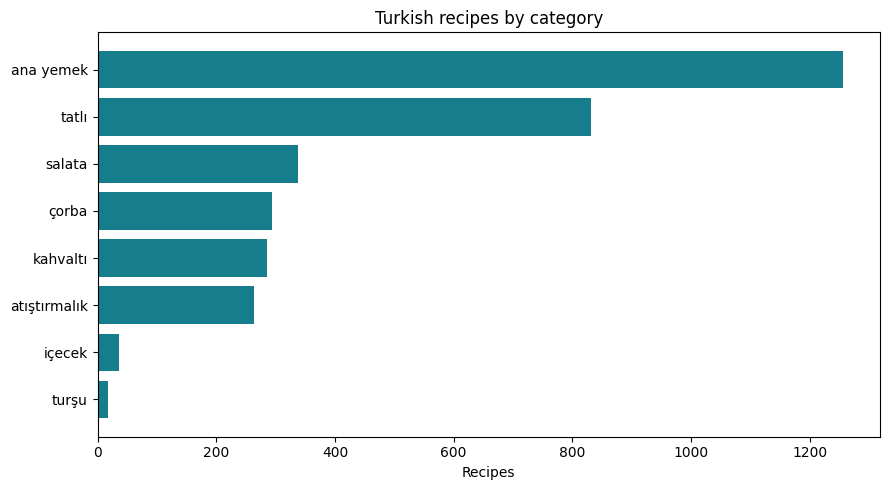

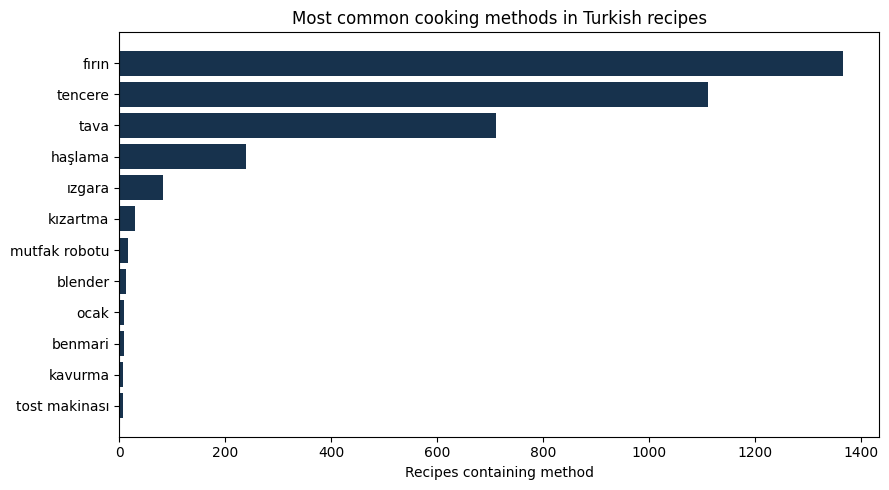

,field,unit_of_analysis,items_with_value,denominator,coverage_pct
0,category,recipes,3320,3320,100.00
1,difficulty,recipes,3320,3320,100.00
2,servings,recipes,68,3320,2.05
3,preparation_minutes,recipes,352,3320,10.60
4,cooking_minutes,recipes,1526,3320,45.96
5,ingredient_amount,ingredient_items,24528,29816,82.26
6,ingredient_unit,ingredient_items,23251,29816,77.98
7,ingredient_amount_and_unit,ingredient_items,23155,29816,77.66


,time_field,valid_nonnegative_values,coverage_pct,median_minutes,q1_minutes,q3_minutes,values_over_240_minutes_for_review,maximum_minutes
0,preparation,352,10.60,20.0,10.0,30.0,9,3600.0
1,cooking,1526,45.96,25.0,20.0,35.0,8,3600.0


,recipes_in_source,recipes_with_ingredients,median_ingredient_count,unique_normalized_terms,sample_size,category_count,difficulty_count,recipes_with_instructions,median_instruction_steps,ingredient_items,ingredient_items_with_amount,ingredient_items_with_unit,median_preparation_minutes,median_cooking_minutes
0,3320,3320,9.0,1276,3320,8,3,3320,11.0,29816,24528,23251,20.0,25.0


Preparation and cooking time values above 240 minutes are retained and flagged for source review.
Recipe proportions and ingredient-detail coverage use different denominators, shown in the coverage table.


In [7]:
turkish_df["category"] = turkish_df["category"].fillna("Unspecified").replace("", "Unspecified")
turkish_df["difficulty"] = turkish_df["difficulty"].fillna("Unspecified").replace("", "Unspecified")

turkish_category_counts = turkish_df["category"].value_counts()
turkish_categories = pd.DataFrame({
    "category": turkish_category_counts.index,
    "recipes": turkish_category_counts.values,
})
turkish_categories["share_pct"] = (
    100 * turkish_categories["recipes"] / len(turkish_df)
).round(2)
display(turkish_categories)
turkish_categories.to_csv(OUTPUT_DIR / "turkish_categories.csv", index=False)

turkish_difficulty_counts = turkish_df["difficulty"].value_counts()
turkish_difficulties = pd.DataFrame({
    "difficulty": turkish_difficulty_counts.index,
    "recipes": turkish_difficulty_counts.values,
})
turkish_difficulties["share_pct"] = (
    100 * turkish_difficulties["recipes"] / len(turkish_df)
).round(2)
display(turkish_difficulties)
turkish_difficulties.to_csv(OUTPUT_DIR / "turkish_difficulty.csv", index=False)

method_counts = Counter(
    method
    for methods in turkish_df["cooking_methods"]
    if isinstance(methods, list)
    for method in set(method for method in methods if isinstance(method, str) and method.strip())
)
turkish_methods = pd.DataFrame([
    {"cooking_method": method, "recipes": count, "share_pct": round(100 * count / len(turkish_df), 2)}
    for method, count in method_counts.most_common()
])
display(turkish_methods.head(15))
turkish_methods.to_csv(OUTPUT_DIR / "turkish_cooking_methods.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(turkish_categories["category"][::-1], turkish_categories["recipes"][::-1], color="#167d8d")
ax.set_title("Turkish recipes by category")
ax.set_xlabel("Recipes")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "turkish_categories.png", dpi=160)
plt.show()

top_methods = turkish_methods.head(12)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_methods["cooking_method"][::-1], top_methods["recipes"][::-1], color="#17324d")
ax.set_title("Most common cooking methods in Turkish recipes")
ax.set_xlabel("Recipes containing method")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "turkish_cooking_methods.png", dpi=160)
plt.show()

coverage_rows = []
for field, label in (
    ("category", "category"),
    ("difficulty", "difficulty"),
    ("servings", "servings"),
    ("preparation_minutes", "preparation_minutes"),
    ("cooking_minutes", "cooking_minutes"),
):
    values = turkish_df[field]
    present = values.notna() & values.astype(str).str.strip().ne("")
    coverage_rows.append({
        "field": label,
        "unit_of_analysis": "recipes",
        "items_with_value": int(present.sum()),
        "denominator": len(turkish_df),
        "coverage_pct": round(100 * present.mean(), 2),
    })

time_rows = []
time_summaries = {}
for field, label in (
    ("preparation_minutes", "preparation"),
    ("cooking_minutes", "cooking"),
):
    numeric = pd.to_numeric(turkish_df[field], errors="coerce")
    valid = numeric.notna() & numeric.ge(0)
    usable = numeric[valid]
    time_summaries[field] = {
        "valid_count": int(valid.sum()),
        "median": float(usable.median()) if not usable.empty else None,
    }
    time_rows.append({
        "time_field": label,
        "valid_nonnegative_values": int(valid.sum()),
        "coverage_pct": round(100 * valid.mean(), 2),
        "median_minutes": float(usable.median()) if not usable.empty else None,
        "q1_minutes": float(usable.quantile(0.25)) if not usable.empty else None,
        "q3_minutes": float(usable.quantile(0.75)) if not usable.empty else None,
        "values_over_240_minutes_for_review": int((usable > 240).sum()),
        "maximum_minutes": float(usable.max()) if not usable.empty else None,
    })

ingredient_details = [
    detail
    for details in turkish_df["ingredient_details"]
    if isinstance(details, list)
    for detail in details
    if isinstance(detail, dict)
]
ingredient_total = len(ingredient_details)
for label, predicate in (
    ("ingredient_amount", lambda detail: detail.get("amount") is not None and str(detail.get("amount")).strip() != ""),
    ("ingredient_unit", lambda detail: detail.get("unit") is not None and str(detail.get("unit")).strip() != ""),
    ("ingredient_amount_and_unit", lambda detail: (
        detail.get("amount") is not None and str(detail.get("amount")).strip() != ""
        and detail.get("unit") is not None and str(detail.get("unit")).strip() != ""
    )),
):
    present_count = sum(predicate(detail) for detail in ingredient_details)
    coverage_rows.append({
        "field": label,
        "unit_of_analysis": "ingredient_items",
        "items_with_value": present_count,
        "denominator": ingredient_total,
        "coverage_pct": round(100 * present_count / ingredient_total, 2) if ingredient_total else 0,
    })

turkish_coverage = pd.DataFrame(coverage_rows)
turkish_time_summary = pd.DataFrame(time_rows)
display(turkish_coverage)
display(turkish_time_summary)
turkish_coverage.to_csv(OUTPUT_DIR / "turkish_field_coverage.csv", index=False)
turkish_time_summary.to_csv(OUTPUT_DIR / "turkish_time_summary.csv", index=False)

instruction_step_counts = turkish_df["instructions"].map(
    lambda steps: len(steps) if isinstance(steps, list) else 0
)
turkish_profile = pd.DataFrame([{
    "recipes_in_source": len(turkish_df),
    "recipes_with_ingredients": int(turkish_df["ingredients"].map(bool).sum()),
    "median_ingredient_count": float(turkish_df["ingredients"].map(len).median()),
    "unique_normalized_terms": len(ingredient_frequencies["turkish_recipes"]),
    "sample_size": len(turkish_df),
    "category_count": int(turkish_df["category"].nunique()),
    "difficulty_count": int(turkish_df["difficulty"].nunique()),
    "recipes_with_instructions": int(instruction_step_counts.gt(0).sum()),
    "median_instruction_steps": float(instruction_step_counts.median()),
    "ingredient_items": ingredient_total,
    "ingredient_items_with_amount": int(turkish_coverage.loc[
        turkish_coverage["field"] == "ingredient_amount", "items_with_value"
    ].iloc[0]),
    "ingredient_items_with_unit": int(turkish_coverage.loc[
        turkish_coverage["field"] == "ingredient_unit", "items_with_value"
    ].iloc[0]),
    "median_preparation_minutes": time_summaries["preparation_minutes"]["median"],
    "median_cooking_minutes": time_summaries["cooking_minutes"]["median"],
}])
display(turkish_profile)
turkish_profile.to_csv(OUTPUT_DIR / "turkish_recipe_profile.csv", index=False)

print("Preparation and cooking time values above 240 minutes are retained and flagged for source review.")
print("Recipe proportions and ingredient-detail coverage use different denominators, shown in the coverage table.")

## 8. FoodKeeper storage-data coverage

FoodKeeper remains a separate source. The following checks identify which storage duration fields have numeric ranges; they do not map US product categories to Turkish recipe ingredients or establish food-safety advice.

,field,numeric_values,nonempty_pct
4,DOP_Refrigerate_Max,235,35.6
5,DOP_Refrigerate_Min,235,35.6
0,DOP_Freeze_Max,196,29.7
2,DOP_Pantry_Max,196,29.7
3,DOP_Pantry_Min,196,29.7
1,DOP_Freeze_Min,196,29.7
12,Refrigerate_After_Opening_Max,145,21.9
13,Refrigerate_After_Opening_Min,145,21.9
6,Freeze_Max,143,21.6
7,Freeze_Min,143,21.6


,category,product_rules
0,Shelf Stable Foods,104
1,Produce,101
2,Meat,88
3,Baked Goods,82
4,"Condiments, Sauces & Canned Goods",52
5,Dairy Products & Eggs,46
6,Deli & Prepared Foods,36
7,Beverages,34
8,"Grains, Beans & Pasta",30
9,Poultry,27


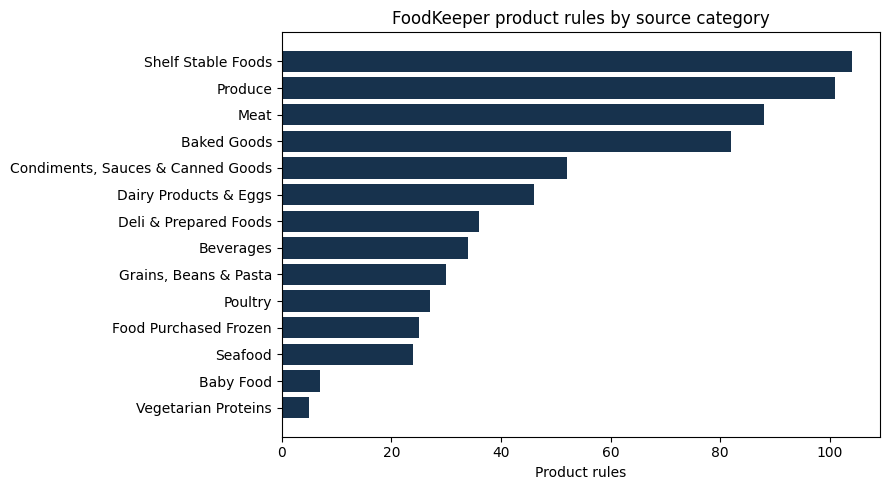

FoodKeeper rows: 661
Rows with at least one numeric min/max duration: 647


In [8]:
foodkeeper = pd.read_json(FOODKEEPER_PATH, lines=True)
storage_columns = sorted({
    key
    for record in foodkeeper["storage_fields"]
    for key in record
})
storage_rows = []
for column in storage_columns:
    if column.endswith(("_Min", "_Max")):
        numeric = pd.to_numeric(foodkeeper["storage_fields"].map(lambda row: row.get(column)), errors="coerce")
        storage_rows.append({
            "field": column,
            "numeric_values": int(numeric.notna().sum()),
            "nonempty_pct": round(100 * numeric.notna().mean(), 1),
        })
storage_coverage = pd.DataFrame(storage_rows).sort_values("numeric_values", ascending=False)
display(storage_coverage)
storage_coverage.to_csv(OUTPUT_DIR / "foodkeeper_storage_field_coverage.csv", index=False)

category_counts = foodkeeper["category_name"].fillna("Unknown").value_counts().head(15)
display(category_counts.rename_axis("category").reset_index(name="product_rules"))
category_counts.rename_axis("category").reset_index(name="product_rules").to_csv(
    OUTPUT_DIR / "foodkeeper_categories.csv", index=False
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(category_counts.index[::-1], category_counts.values[::-1], color="#17324d")
ax.set_title("FoodKeeper product rules by source category")
ax.set_xlabel("Product rules")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "foodkeeper_categories.png", dpi=160)
plt.show()

print("FoodKeeper rows:", len(foodkeeper))
print("Rows with at least one numeric min/max duration:",
      int(foodkeeper["storage_fields"].map(
          lambda row: any(
              key.endswith(("_Min", "_Max")) and pd.to_numeric(value, errors="coerce") == pd.to_numeric(value, errors="coerce")
              for key, value in row.items()
          )
      ).sum()))

## 9. FoodKeeper duration distributions and date-fallback readiness

Compare the FoodKeeper storage scenarios separately. Keep the source's native unit and raw `DOP_*` labels visible; a rough day conversion (hours=24, weeks=7, months=30, years=365) is only for descriptive comparison. These records are storage guidance ranges, not product expiry dates, and do not establish safe consumption. Text-only and unknown-unit entries remain visible as quality flags.

,storage_scenario,rules_with_any_bound,rules_with_numeric_min_and_max,text_or_non_numeric_bound_entries,numeric_ranges_with_unknown_metric,numeric_ranges_with_min_greater_than_max,median_minimum_days_known_metric,median_maximum_days_known_metric,maximum_reported_duration_days_known_metric,day_conversion_assumption
0,Pantry,98,97,0,0,0,180.0,180.0,3650.0,hour=1/24; day=1; week=7; month=30; year=365
1,Pantry_After_Opening,75,75,0,0,0,180.0,180.0,1460.0,hour=1/24; day=1; week=7; month=30; year=365
2,DOP_Pantry,196,196,0,0,0,360.0,365.0,1825.0,hour=1/24; day=1; week=7; month=30; year=365
3,Refrigerate,129,129,0,0,0,3.0,5.0,730.0,hour=1/24; day=1; week=7; month=30; year=365
4,Refrigerate_After_Opening,145,145,0,0,0,7.0,10.0,540.0,hour=1/24; day=1; week=7; month=30; year=365
5,DOP_Refrigerate,235,235,0,0,0,7.0,7.0,730.0,hour=1/24; day=1; week=7; month=30; year=365
6,Refrigerate_After_Thawing,6,3,3,0,0,5.0,5.0,7.0,hour=1/24; day=1; week=7; month=30; year=365
7,Freeze,143,143,0,0,0,180.0,180.0,730.0,hour=1/24; day=1; week=7; month=30; year=365
8,DOP_Freeze,196,196,0,0,0,120.0,270.0,730.0,hour=1/24; day=1; week=7; month=30; year=365


,storage_scenario,source_metric,numeric_min_max_ranges
0,Pantry,Days,14
1,Pantry,Hours,4
2,Pantry,Months,48
3,Pantry,Weeks,8
4,Pantry,Years,23
5,Pantry_After_Opening,Days,2
6,Pantry_After_Opening,Hours,1
7,Pantry_After_Opening,Months,48
8,Pantry_After_Opening,Weeks,7
9,Pantry_After_Opening,Years,17


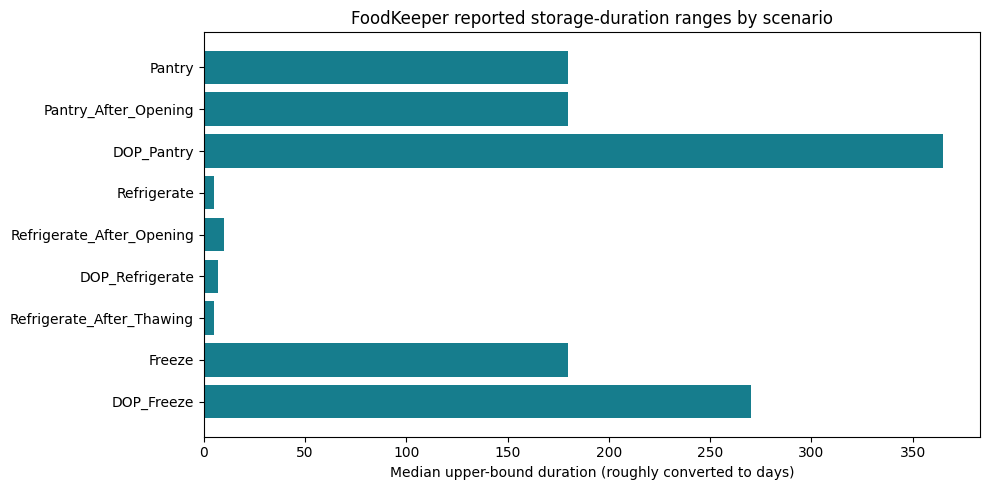

DOP_* is kept as a literal source field prefix; its meaning is not inferred here.
Unknown units, text bounds, and reversed numeric ranges are quality flags, not safety judgments.


In [9]:
storage_scenarios = [
    ("Pantry", "Pantry"),
    ("Pantry_After_Opening", "Pantry_After_Opening"),
    ("DOP_Pantry", "DOP_Pantry"),
    ("Refrigerate", "Refrigerate"),
    ("Refrigerate_After_Opening", "Refrigerate_After_Opening"),
    ("DOP_Refrigerate", "DOP_Refrigerate"),
    ("Refrigerate_After_Thawing", "Refrigerate_After_Thawing"),
    ("Freeze", "Freeze"),
    ("DOP_Freeze", "DOP_Freeze"),
]
metric_to_days = {
    "hour": 1 / 24, "hours": 1 / 24,
    "day": 1, "days": 1,
    "week": 7, "weeks": 7,
    "month": 30, "months": 30,
    "year": 365, "years": 365,
}
duration_rows = []
metric_rows = []
for field_prefix, scenario_label in storage_scenarios:
    min_field = f"{field_prefix}_Min"
    max_field = f"{field_prefix}_Max"
    metric_field = f"{field_prefix}_Metric"
    raw_bounds = [
        (row.get(min_field), row.get(max_field), row.get(metric_field))
        for row in foodkeeper["storage_fields"]
    ]
    any_bound = [
        min_value not in (None, "") or max_value not in (None, "")
        for min_value, max_value, _ in raw_bounds
    ]
    numeric_ranges = []
    lower_days = []
    upper_days = []
    text_bound_entries = 0
    unknown_unit_ranges = 0
    reversed_ranges = 0
    metrics = Counter()
    for min_value, max_value, metric in raw_bounds:
        min_number = pd.to_numeric(min_value, errors="coerce")
        max_number = pd.to_numeric(max_value, errors="coerce")
        min_numeric = pd.notna(min_number)
        max_numeric = pd.notna(max_number)
        if min_value not in (None, "") and not min_numeric:
            text_bound_entries += 1
        if max_value not in (None, "") and not max_numeric:
            text_bound_entries += 1
        if not (min_numeric and max_numeric):
            continue
        numeric_ranges.append((float(min_number), float(max_number)))
        metric_label = str(metric).strip()
        metrics[metric_label or "Unspecified"] += 1
        multiplier = metric_to_days.get(metric_label.casefold())
        if multiplier is None:
            unknown_unit_ranges += 1
            continue
        if min_number > max_number:
            reversed_ranges += 1
            continue
        lower_days.append(float(min_number) * multiplier)
        upper_days.append(float(max_number) * multiplier)
    metric_rows.extend({
        "storage_scenario": scenario_label,
        "source_metric": metric_label,
        "numeric_min_max_ranges": count,
    } for metric_label, count in sorted(metrics.items()))
    duration_rows.append({
        "storage_scenario": scenario_label,
        "rules_with_any_bound": int(sum(any_bound)),
        "rules_with_numeric_min_and_max": len(numeric_ranges),
        "text_or_non_numeric_bound_entries": text_bound_entries,
        "numeric_ranges_with_unknown_metric": unknown_unit_ranges,
        "numeric_ranges_with_min_greater_than_max": reversed_ranges,
        "median_minimum_days_known_metric": float(pd.Series(lower_days).median()) if lower_days else None,
        "median_maximum_days_known_metric": float(pd.Series(upper_days).median()) if upper_days else None,
        "maximum_reported_duration_days_known_metric": max(upper_days) if upper_days else None,
        "day_conversion_assumption": "hour=1/24; day=1; week=7; month=30; year=365",
    })

foodkeeper_duration_profile = pd.DataFrame(duration_rows)
foodkeeper_metric_profile = pd.DataFrame(metric_rows)
display(foodkeeper_duration_profile)
display(foodkeeper_metric_profile)
foodkeeper_duration_profile.to_csv(OUTPUT_DIR / "foodkeeper_storage_scenarios.csv", index=False)
foodkeeper_metric_profile.to_csv(OUTPUT_DIR / "foodkeeper_storage_scenario_units.csv", index=False)

plot_data = foodkeeper_duration_profile.dropna(subset=["median_maximum_days_known_metric"])
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(
    plot_data["storage_scenario"][::-1],
    plot_data["median_maximum_days_known_metric"][::-1],
    color="#167d8d",
)
ax.set_xlabel("Median upper-bound duration (roughly converted to days)")
ax.set_title("FoodKeeper reported storage-duration ranges by scenario")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "foodkeeper_duration_by_scenario.png", dpi=160)
plt.show()

print("DOP_* is kept as a literal source field prefix; its meaning is not inferred here.")
print("Unknown units, text bounds, and reversed numeric ranges are quality flags, not safety judgments.")

## 10. update: impact scenarios and data readiness

The UNEP Food Waste Index 2024 country estimate of **102 kg of household food waste per person per year for Türkiye** is used only as an external scenario baseline ([UNEP report](https://www.unep.org/resources/publication/food-waste-index-report-2024)). This is not a measurement of FoodWise impact. The calculations below show hypothetical 1%, 5%, and 10% reductions for one-person and four-person households; they do not imply that FoodWise can deliver those reductions.

Open Food Facts/barcode data, municipal donation and waste logs, and Turkish nutritional/diet suitability data are not included in this workspace. Their absence is recorded as an EDA limitation rather than filled with invented observations. In particular, the Turkish source schema has no calorie/macronutrient or clinically validated diet-suitability fields.

,household_size_people,scenario_reduction_pct,baseline_kg_per_year,hypothetical_kg_avoided_per_year,source_baseline_kg_per_person_year,interpretation
0,1,0.0,102.0,0.00,102.0,scenario only; not observed or attributable to...
1,1,1.0,102.0,1.02,102.0,scenario only; not observed or attributable to...
2,1,5.0,102.0,5.10,102.0,scenario only; not observed or attributable to...
3,1,10.0,102.0,10.20,102.0,scenario only; not observed or attributable to...
4,4,0.0,408.0,0.00,102.0,scenario only; not observed or attributable to...
5,4,1.0,408.0,4.08,102.0,scenario only; not observed or attributable to...
6,4,5.0,408.0,20.40,102.0,scenario only; not observed or attributable to...
7,4,10.0,408.0,40.80,102.0,scenario only; not observed or attributable to...


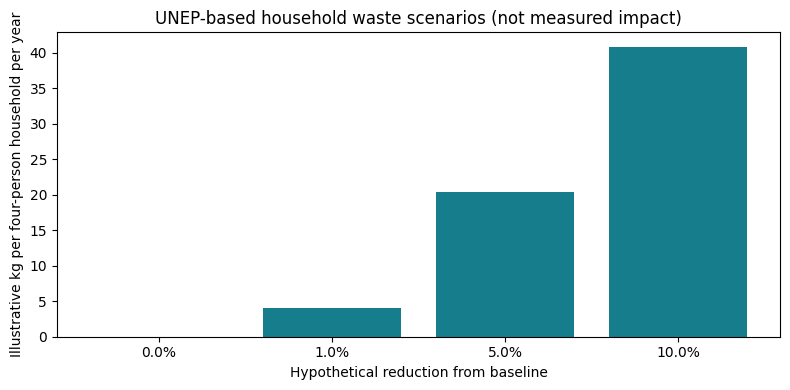

,suggested_data_or_question,present_in_current_processed_run,eda_status,needed_for_future_eda
0,Open Food Facts barcode/product profile,False,not analyzed: no Open Food Facts records/API e...,"sampled Turkish product records with barcode, ..."
1,Municipal kitchen / food-bank scenario,False,"not analyzed: no partner donation, inventory, ...","de-identified dated quantities received, used,..."
2,Turkish diet-specific / diabetes suitability,False,not assessable: Turkish recipe data lacks nutr...,validated Turkish nutrition/allergen data and ...
3,Observed household waste reduction,False,scenario calculation only; no baseline or post...,paired pre/post household or partner-site weig...


Turkish recipe fields available: ['category', 'cooking_methods', 'cooking_minutes', 'difficulty', 'ingredient_count', 'ingredient_details', 'ingredient_signature', 'ingredients', 'instructions', 'language', 'name', 'normalized_title', 'preparation_minutes', 'recipe_id', 'servings', 'source', 'source_ingredients', 'source_record']
Turkish nutrition/diet fields absent: ['allergens', 'calories', 'calories_source', 'carbohydrates', 'dietary_suitability', 'energy', 'fat', 'protein', 'protein_source']


In [10]:
unep_household_waste_kg_per_person_year = 102.0
scenario_reduction_rates = [0.00, 0.01, 0.05, 0.10]
scenario_household_sizes = [1, 4]
impact_scenario_rows = []
for household_size in scenario_household_sizes:
    baseline = unep_household_waste_kg_per_person_year * household_size
    for reduction_rate in scenario_reduction_rates:
        impact_scenario_rows.append({
            "household_size_people": household_size,
            "scenario_reduction_pct": round(100 * reduction_rate, 1),
            "baseline_kg_per_year": baseline,
            "hypothetical_kg_avoided_per_year": baseline * reduction_rate,
            "source_baseline_kg_per_person_year": unep_household_waste_kg_per_person_year,
            "interpretation": "scenario only; not observed or attributable to FoodWise",
        })
impact_scenarios = pd.DataFrame(impact_scenario_rows)
display(impact_scenarios)
impact_scenarios.to_csv(OUTPUT_DIR / "unep_household_waste_scenarios.csv", index=False)

four_person_scenarios = impact_scenarios[
    impact_scenarios["household_size_people"] == 4
]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    four_person_scenarios["scenario_reduction_pct"].astype(str) + "%",
    four_person_scenarios["hypothetical_kg_avoided_per_year"],
    color="#167d8d",
)
ax.set_xlabel("Hypothetical reduction from baseline")
ax.set_ylabel("Illustrative kg per four-person household per year")
ax.set_title("UNEP-based household waste scenarios (not measured impact)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "unep_household_waste_scenarios.png", dpi=160)
plt.show()

nutrition_fields = {
    "calories", "calories_source", "energy", "protein", "protein_source",
    "carbohydrates", "fat", "allergens", "dietary_suitability",
}
turkish_missing_nutrition_fields = sorted(nutrition_fields - set(turkish_df.columns))
open_food_facts_in_manifest = any(
    "open_food_facts" in source.casefold()
    for source in manifest.get("sources", {})
)
data_readiness = pd.DataFrame([
    {
        "suggested_data_or_question": "Open Food Facts barcode/product profile",
        "present_in_current_processed_run": open_food_facts_in_manifest,
        "eda_status": "not analyzed: no Open Food Facts records/API extract is included",
        "needed_for_future_eda": "sampled Turkish product records with barcode, product name, categories, ingredient text, language/country, and nutrition fields",
    },
    {
        "suggested_data_or_question": "Municipal kitchen / food-bank scenario",
        "present_in_current_processed_run": False,
        "eda_status": "not analyzed: no partner donation, inventory, adoption, or measured waste logs",
        "needed_for_future_eda": "de-identified dated quantities received, used, donated, discarded, discard reason, and recommendations shown/adopted",
    },
    {
        "suggested_data_or_question": "Turkish diet-specific / diabetes suitability",
        "present_in_current_processed_run": not turkish_missing_nutrition_fields,
        "eda_status": "not assessable: Turkish recipe data lacks nutrition, allergen, and validated diet-suitability fields",
        "needed_for_future_eda": "validated Turkish nutrition/allergen data and qualified clinical review; ingredient lists alone are insufficient",
    },
    {
        "suggested_data_or_question": "Observed household waste reduction",
        "present_in_current_processed_run": False,
        "eda_status": "scenario calculation only; no baseline or post-use waste measurements",
        "needed_for_future_eda": "paired pre/post household or partner-site weighing with consistent scope and period",
    },
])
display(data_readiness)
data_readiness.to_csv(OUTPUT_DIR / "assignment1_data_readiness.csv", index=False)
print("Turkish recipe fields available:", sorted(set(turkish_df.columns)))
print("Turkish nutrition/diet fields absent:", turkish_missing_nutrition_fields)

## 11. Project research questions: EDA evidence map

The project is organized around three research questions. This evidence map distinguishes descriptive EDA evidence from questions that still require model evaluation or field data.

In [11]:
inventory_path = ROOT / "data" / "example_inventory.json"
inventory_evidence = "not available"
if inventory_path.is_file():
    inventory_example = json.loads(inventory_path.read_text(encoding="utf-8"))
    inventory_terms = {
        " ".join(unicodedata.normalize("NFKC", str(item.get("ingredient", ""))).casefold().split())
        for item in inventory_example.get("items", [])
        if item.get("ingredient")
    }
    coverage_rows = []
    with (ROOT / "data" / "recipes_sample.jsonl").open(encoding="utf-8") as recipe_source:
        for line in recipe_source:
            if not line.strip():
                continue
            recipe = json.loads(line)
            recipe_terms = set(recipe.get("ingredients", []))
            if recipe_terms:
                matched = recipe_terms & inventory_terms
                coverage_rows.append({
                    "recipe_id": recipe.get("recipe_id"),
                    "ingredient_count": len(recipe_terms),
                    "matched_ingredients_count": len(matched),
                    "ingredient_coverage": len(matched) / len(recipe_terms),
                })
    coverage = pd.DataFrame(coverage_rows)
    coverage.to_csv(OUTPUT_DIR / "assignment1_inventory_coverage.csv", index=False)
    inventory_evidence = (
        f"{len(coverage):,} Food.com recipes; "
        f"{int((coverage['ingredient_coverage'] >= 0.25).sum()):,} "
        f"({100 * (coverage['ingredient_coverage'] >= 0.25).mean():.2f}%) at >=25% exact lexical coverage; "
        f"{int((coverage['ingredient_coverage'] == 1).sum())} at 100%; "
        f"illustrative inventory has {len(inventory_example.get('items', []))} items; "
        "coverage was recomputed from the current sample."
    )

research_question_evidence = pd.DataFrame([
    {
        "project_research_question": (
            "1. How do available English and Turkish recipe datasets differ in composition and data quality, "
            "and what preprocessing is needed for Turkish-focused ingredient matching?"
        ),
        "evidence_in_assignment1_eda": (
            "Source counts, ingredient-count distributions, source-specific term frequencies, Turkish category "
            "and cooking-method profiles, quantity/unit coverage, normalization variants, and duplicate candidates."
        ),
        "boundary": (
            "Language-specific terms remain separate; no semantic ingredient matching or unified cross-language "
            "comparison is validated."
        ),
    },
    {
        "project_research_question": (
            "2. How well does an illustrative pantry inventory match recipes using normalized ingredient overlap, "
            "and what should be evaluated when comparing ingredient-weighting methods?"
        ),
        "evidence_in_assignment1_eda": inventory_evidence,
        "boundary": (
            "The overlap result is for one illustrative English inventory against the Food.com sample. "
            "IDF weights are described, but no controlled Jaccard-versus-TF-IDF ranking evaluation is run."
        ),
    },
    {
        "project_research_question": (
            "3. How could expiry-aware, barcode-assisted pantry management prioritize recipes and support measurable "
            "waste reduction while respecting data and safety limits?"
        ),
        "evidence_in_assignment1_eda": (
            "FoodKeeper storage scenarios and field coverage, a proposed barcode lookup workflow, data-readiness "
            "gaps, and hypothetical UNEP-based household waste scenarios."
        ),
        "boundary": (
            "No Open Food Facts barcode records, user evaluation, partner pilot, or observed waste measurements "
            "are available; storage duration is not an expiry date or safety guarantee."
        ),
    },
])
display(research_question_evidence)
research_question_evidence.to_csv(OUTPUT_DIR / "assignment1_research_question_evidence.csv", index=False)

,project_research_question,evidence_in_assignment1_eda,boundary
0,1. How do available English and Turkish recipe...,"Source counts, ingredient-count distributions,...",Language-specific terms remain separate; no se...
1,2. How well does an illustrative pantry invent...,"8,000 Food.com recipes; 1,502 (18.77%) at >=25...",The overlap result is for one illustrative Eng...
2,"3. How could expiry-aware, barcode-assisted pa...",FoodKeeper storage scenarios and field coverag...,"No Open Food Facts barcode records, user evalu..."


## 12. Supplementary project EDA: restored Food.com visuals

The processed-data sections above retain the source-wide summaries and Turkish/FoodKeeper analyses. This section restores broader exploratory views from the original Food.com notebook: field quality, recipe categories and ingredients, numeric distributions, ingredient co-occurrence, relationships, time trends, and the illustrative inventory-coverage distribution. The detailed Food.com charts use the fixed 8,000-recipe sample; the bounded RecipeNLG detail rows are not treated as a representative random sample. No figure implies a real household inventory, barcode coverage, or measured food-waste impact.

### 12.1 Source scale and field completeness

Compare full processed-source counts on a logarithmic scale with the bounded rows retained for detailed inspection. The second panel reports missing/empty recipe names, ingredient lists, and instructions from the full streamed corpus.

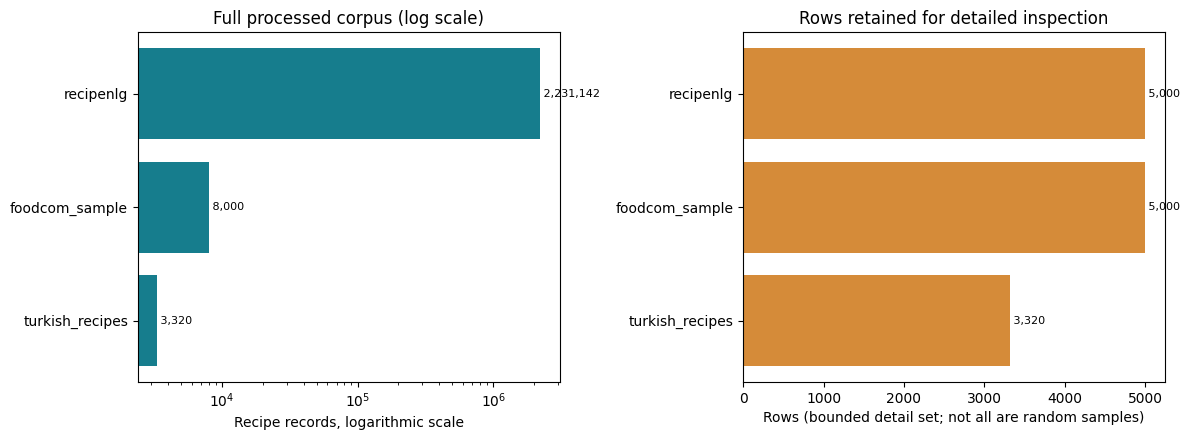

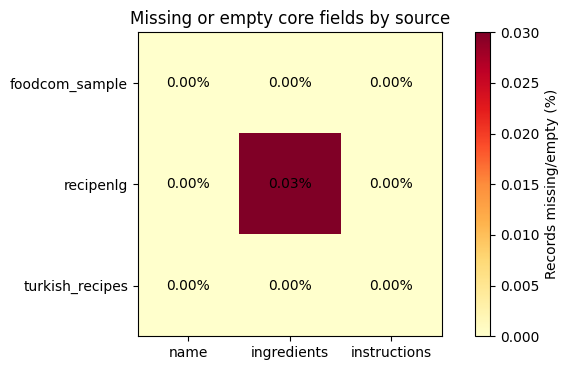

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ordered_sources = source_summary.sort_values("recipes")
axes[0].barh(ordered_sources["source"], ordered_sources["recipes"], color="#167d8d")
axes[0].set_xscale("log")
axes[0].set_title("Full processed corpus (log scale)")
axes[0].set_xlabel("Recipe records, logarithmic scale")
for y, value in enumerate(ordered_sources["recipes"]):
    axes[0].text(value, y, f" {value:,}", va="center", fontsize=8)

sample_order = source_summary.sort_values("sampled_for_detail")
axes[1].barh(sample_order["source"], sample_order["sampled_for_detail"], color="#d58b39")
axes[1].set_title("Rows retained for detailed inspection")
axes[1].set_xlabel("Rows (bounded detail set; not all are random samples)")
for y, value in enumerate(sample_order["sampled_for_detail"]):
    axes[1].text(value, y, f" {value:,}", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "source_scale_and_detail_samples.png", dpi=160)
plt.show()

quality_matrix = quality_report.pivot(
    index="source", columns="field", values="share_pct"
).fillna(0)
quality_matrix = quality_matrix.reindex(columns=["name", "ingredients", "instructions"])
fig, ax = plt.subplots(figsize=(7, 3.8))
image = ax.imshow(quality_matrix.to_numpy(), cmap="YlOrRd", vmin=0)
ax.set_xticks(range(len(quality_matrix.columns)), quality_matrix.columns)
ax.set_yticks(range(len(quality_matrix.index)), quality_matrix.index)
ax.set_title("Missing or empty core fields by source")
for row in range(quality_matrix.shape[0]):
    for column in range(quality_matrix.shape[1]):
        ax.text(column, row, f"{quality_matrix.iloc[row, column]:.2f}%", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Records missing/empty (%)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "core_field_quality_by_source.png", dpi=160)
plt.show()

### 12.2 Food.com categories, ingredients, and numeric distributions

Use the complete reproducible 8,000-row Food.com sample for category/ingredient frequencies and recipe-level distributions. Histograms cap displayed values at each field's 99th percentile for readability; the printed summaries still retain the full data, including extremes.

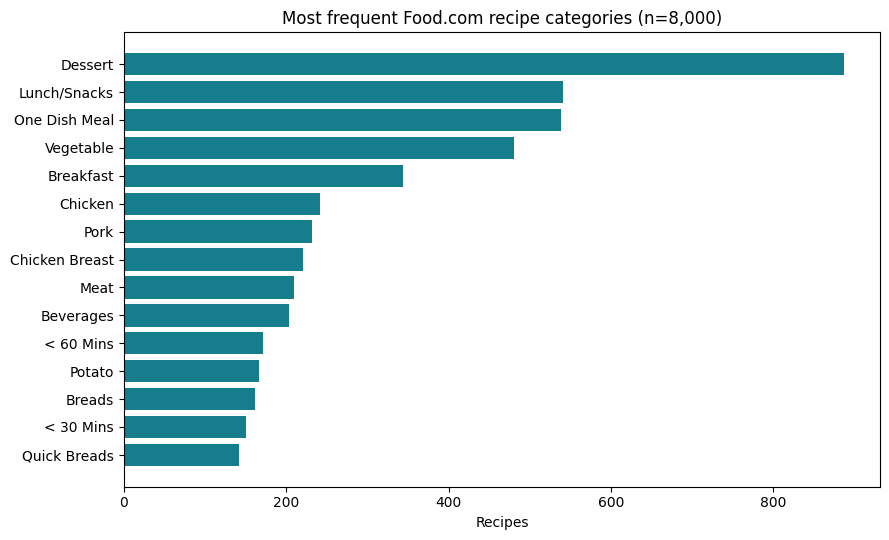

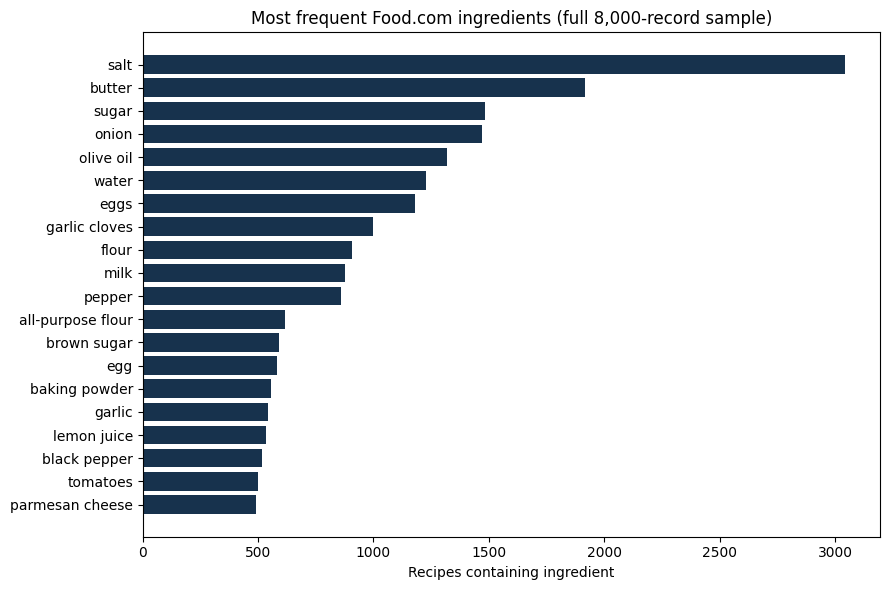

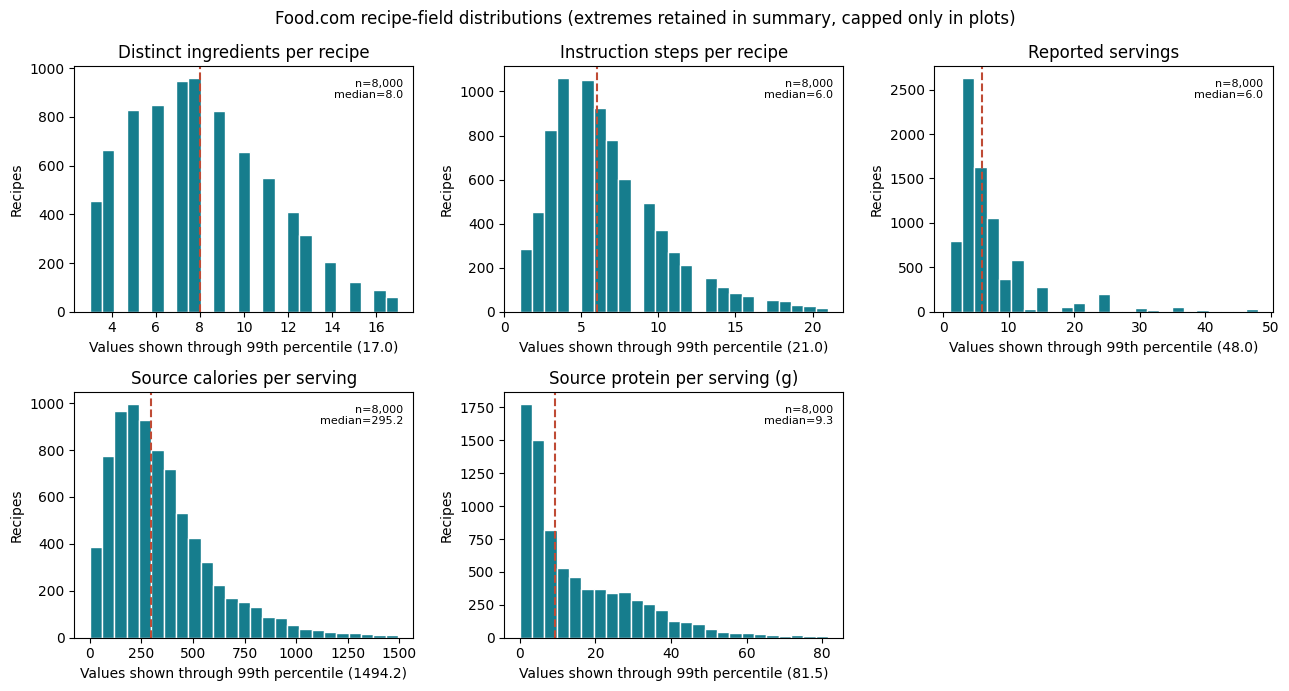

,count,mean,std,min,50%,90%,99%,max
ingredient_count_eda,8000.0,8.117125,3.309007,3.0,8.0,13.0,17.000,20.0
instruction_step_count_eda,8000.0,6.721500,4.128961,1.0,6.0,12.0,21.000,42.0
servings,8000.0,8.358250,13.242680,1.0,6.0,16.0,48.000,608.0
calories_source,8000.0,371.541200,405.181495,0.0,295.2,700.5,1494.178,13967.3
protein_source,8000.0,16.216675,18.371749,0.0,9.3,37.9,81.500,280.0


In [13]:
foodcom_path = ROOT / "data" / "recipes_sample.jsonl"
foodcom_records = [
    json.loads(line)
    for line in foodcom_path.open(encoding="utf-8")
    if line.strip()
]
foodcom_df = pd.DataFrame(foodcom_records)
assert len(foodcom_df) == 8_000, f"Expected the reproducible 8,000-row sample; got {len(foodcom_df)}"
foodcom_df["ingredient_count_eda"] = foodcom_df["ingredients"].map(
    lambda values: len(set(values)) if isinstance(values, list) else 0
)
foodcom_df["instruction_step_count_eda"] = foodcom_df["instructions"].map(
    lambda values: len(values) if isinstance(values, list) else 0
)

category_counts = foodcom_df["category"].fillna("Unspecified").value_counts().head(15)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(category_counts.index[::-1], category_counts.values[::-1], color="#167d8d")
ax.set_title("Most frequent Food.com recipe categories (n=8,000)")
ax.set_xlabel("Recipes")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "foodcom_top_categories.png", dpi=160)
plt.show()

foodcom_top_ingredients = top_ingredients[
    top_ingredients["source"] == "foodcom_sample"
].sort_values("recipe_document_frequency", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    foodcom_top_ingredients["ingredient"][::-1],
    foodcom_top_ingredients["recipe_document_frequency"][::-1],
    color="#17324d",
)
ax.set_title("Most frequent Food.com ingredients (full 8,000-record sample)")
ax.set_xlabel("Recipes containing ingredient")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "foodcom_top_ingredients.png", dpi=160)
plt.show()

numeric_plot_fields = [
    ("ingredient_count_eda", "Distinct ingredients per recipe"),
    ("instruction_step_count_eda", "Instruction steps per recipe"),
    ("servings", "Reported servings"),
    ("calories_source", "Source calories per serving"),
    ("protein_source", "Source protein per serving (g)"),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (field, label) in zip(axes.flat, numeric_plot_fields):
    values = pd.to_numeric(foodcom_df[field], errors="coerce").dropna()
    if values.empty:
        ax.set_visible(False)
        continue
    display_limit = values.quantile(0.99)
    displayed = values[values <= display_limit]
    ax.hist(displayed, bins=25, color="#167d8d", edgecolor="white")
    ax.axvline(values.median(), color="#bf4b35", linestyle="--", linewidth=1.5)
    ax.set_title(label)
    ax.set_xlabel(f"Values shown through 99th percentile ({display_limit:.1f})")
    ax.set_ylabel("Recipes")
    ax.text(
        0.97, 0.95, f"n={len(values):,}\nmedian={values.median():.1f}",
        ha="right", va="top", transform=ax.transAxes, fontsize=8,
    )
axes.flat[-1].axis("off")
fig.suptitle("Food.com recipe-field distributions (extremes retained in summary, capped only in plots)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "foodcom_numeric_distributions.png", dpi=160)
plt.show()

numeric_summary = foodcom_df[
    ["ingredient_count_eda", "instruction_step_count_eda", "servings", "calories_source", "protein_source"]
].describe(percentiles=[0.5, 0.9, 0.99]).T
display(numeric_summary)
numeric_summary.to_csv(OUTPUT_DIR / "foodcom_numeric_summary.csv")

### 12.3 Ingredient co-occurrence and recipe-field relationships

Co-occurrence counts show which ingredient pairs appear together in this sample; they are descriptive and do not imply substitution, flavor compatibility, or safety. Nutrition fields are source-provided values, not independently validated.

,ingredient_pair,recipes
0,butter + salt,878
1,salt + sugar,723
2,pepper + salt,685
3,onion + salt,619
4,eggs + salt,601
5,flour + salt,568
6,salt + water,519
7,olive oil + salt,517
8,butter + sugar,514
9,butter + eggs,477


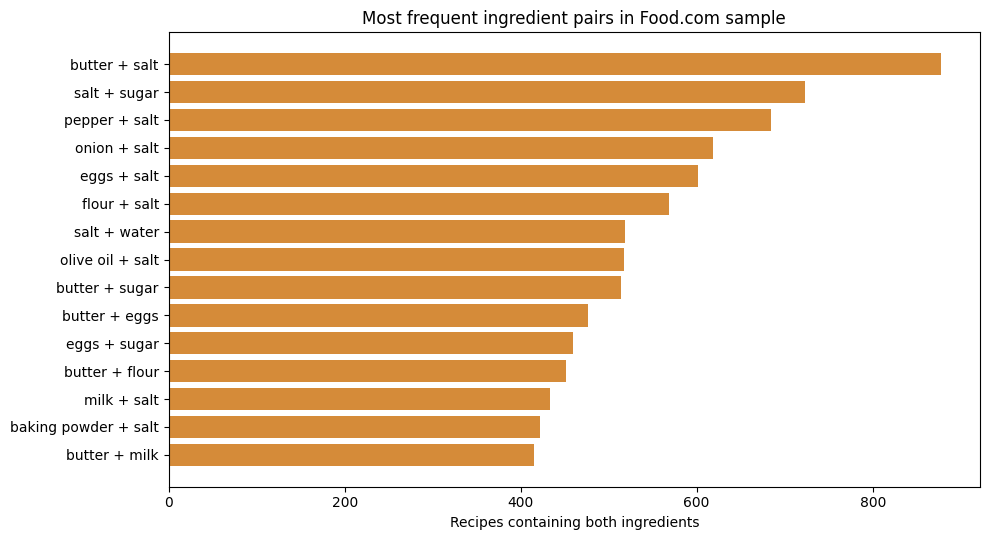

,servings,ingredient_count_eda,instruction_step_count_eda,calories_source,protein_source
servings,1.00,0.15,0.12,-0.25,-0.34
ingredient_count_eda,0.15,1.00,0.25,0.25,0.26
instruction_step_count_eda,0.12,0.25,1.00,0.21,0.14
calories_source,-0.25,0.25,0.21,1.00,0.73
protein_source,-0.34,0.26,0.14,0.73,1.00


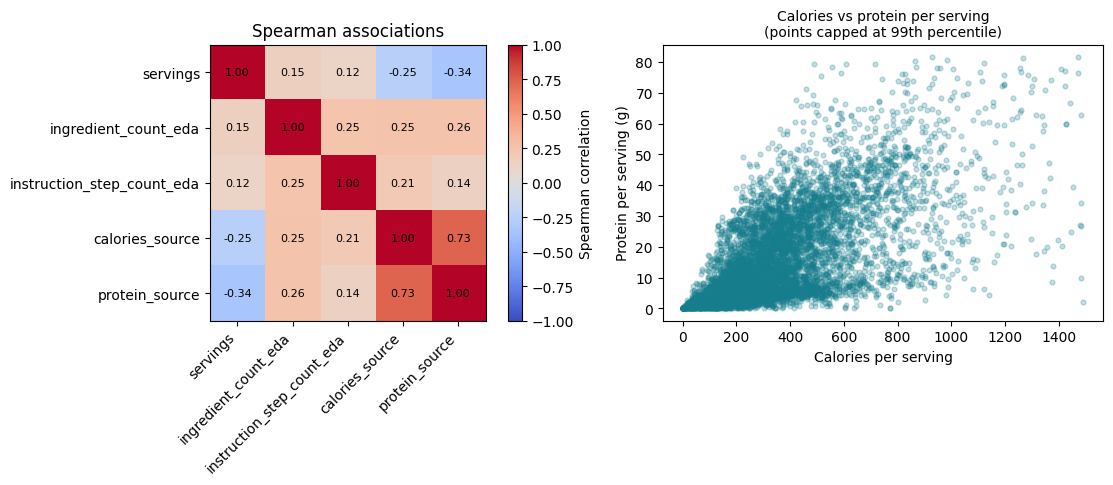

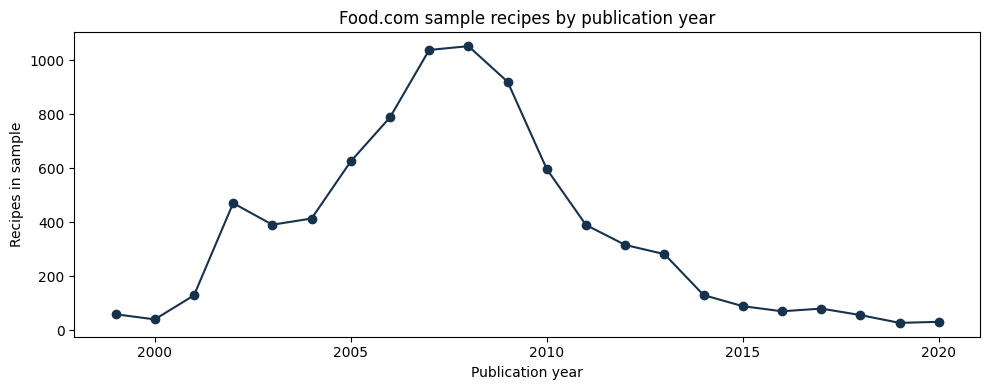

In [14]:
from itertools import combinations

pair_counts = Counter()
for values in foodcom_df["ingredients"]:
    if isinstance(values, list):
        pair_counts.update(combinations(sorted(set(values)), 2))
top_pairs = pd.DataFrame(
    [
        {"ingredient_pair": f"{left} + {right}", "recipes": count}
        for (left, right), count in pair_counts.most_common(15)
    ]
)
display(top_pairs)
top_pairs.to_csv(OUTPUT_DIR / "foodcom_top_ingredient_pairs.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top_pairs["ingredient_pair"][::-1], top_pairs["recipes"][::-1], color="#d58b39")
ax.set_title("Most frequent ingredient pairs in Food.com sample")
ax.set_xlabel("Recipes containing both ingredients")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "foodcom_ingredient_cooccurrence.png", dpi=160)
plt.show()

relationship_fields = [
    "servings", "ingredient_count_eda", "instruction_step_count_eda",
    "calories_source", "protein_source",
]
relationship_data = foodcom_df[relationship_fields].apply(pd.to_numeric, errors="coerce")
spearman = relationship_data.corr(method="spearman")
display(spearman.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
image = axes[0].imshow(spearman.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(spearman.columns)), spearman.columns, rotation=45, ha="right")
axes[0].set_yticks(range(len(spearman.index)), spearman.index)
axes[0].set_title("Spearman associations")
for row in range(spearman.shape[0]):
    for column in range(spearman.shape[1]):
        value = spearman.iloc[row, column]
        axes[0].text(column, row, f"{value:.2f}" if pd.notna(value) else "NA", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=axes[0], label="Spearman correlation")

scatter_data = foodcom_df[["calories_source", "protein_source"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()
calorie_limit = scatter_data["calories_source"].quantile(0.99)
protein_limit = scatter_data["protein_source"].quantile(0.99)
scatter_data = scatter_data[
    scatter_data["calories_source"].le(calorie_limit)
    & scatter_data["protein_source"].le(protein_limit)
]
axes[1].scatter(
    scatter_data["calories_source"], scatter_data["protein_source"],
    alpha=0.25, s=12, color="#167d8d",
)
axes[1].set_title("Calories vs protein per serving\n(points capped at 99th percentile)", fontsize=10)
axes[1].set_xlabel("Calories per serving")
axes[1].set_ylabel("Protein per serving (g)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "foodcom_recipe_field_relationships.png", dpi=160)
plt.show()

foodcom_df["publication_year"] = pd.to_datetime(
    foodcom_df["published_at"], errors="coerce", utc=True
).dt.year
year_counts = foodcom_df["publication_year"].dropna().astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(year_counts.index, year_counts.values, marker="o", color="#17324d")
ax.set_title("Food.com sample recipes by publication year")
ax.set_xlabel("Publication year")
ax.set_ylabel("Recipes in sample")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "foodcom_publication_years.png", dpi=160)
plt.show()

### 12.4 Inventory coverage and Turkish field completeness

The inventory is a nine-item illustrative example, not a recruited household or community-kitchen inventory. Coverage uses exact normalized ingredient names and does not establish meal viability. Turkish recipe-field and ingredient-detail percentages have different denominators, shown separately.

Illustrative inventory items: 9; not an observed pantry.


,threshold,recipes,share_pct
0,>=25%,1502,18.77
1,>=50%,119,1.49
2,100%,1,0.01


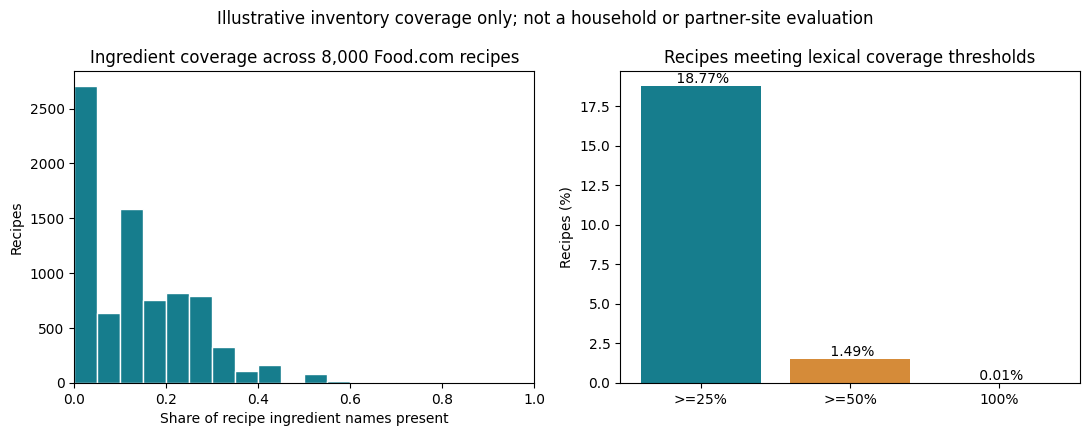

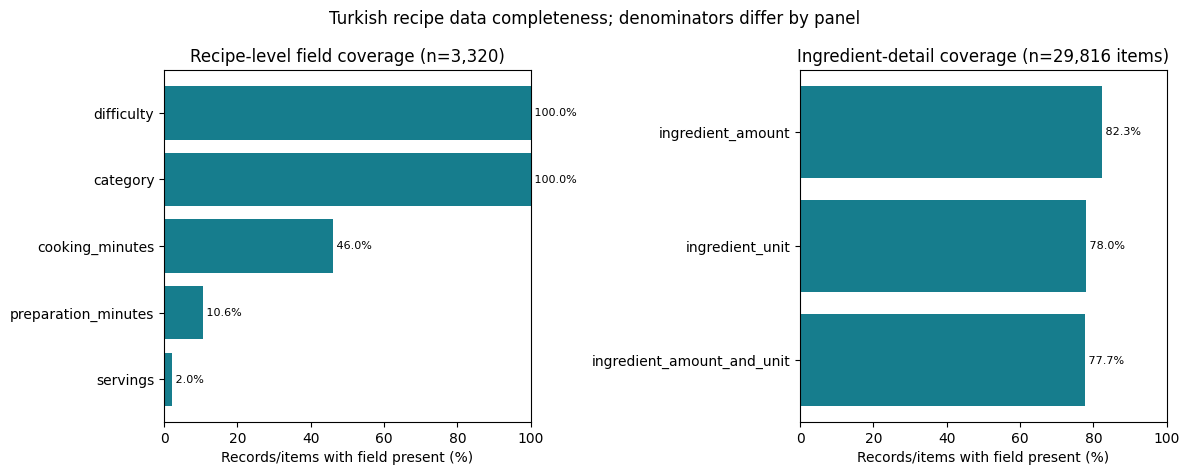

In [15]:
coverage = pd.read_csv(OUTPUT_DIR / "assignment1_inventory_coverage.csv")
inventory_example = json.loads((ROOT / "data" / "example_inventory.json").read_text(encoding="utf-8"))
coverage_thresholds = pd.DataFrame([
    {
        "threshold": label,
        "recipes": int(coverage["ingredient_coverage"].ge(threshold).sum()),
        "share_pct": round(100 * coverage["ingredient_coverage"].ge(threshold).mean(), 2),
    }
    for threshold, label in ((0.25, ">=25%"), (0.50, ">=50%"), (1.00, "100%"))
])
print(f"Illustrative inventory items: {len(inventory_example.get('items', []))}; not an observed pantry.")
display(coverage_thresholds)
coverage_thresholds.to_csv(OUTPUT_DIR / "inventory_coverage_thresholds.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].hist(coverage["ingredient_coverage"], bins=20, color="#167d8d", edgecolor="white")
axes[0].set_title("Ingredient coverage across 8,000 Food.com recipes")
axes[0].set_xlabel("Share of recipe ingredient names present")
axes[0].set_ylabel("Recipes")
axes[0].set_xlim(0, 1)
axes[1].bar(
    coverage_thresholds["threshold"], coverage_thresholds["share_pct"],
    color=["#167d8d", "#d58b39", "#17324d"],
)
axes[1].set_title("Recipes meeting lexical coverage thresholds")
axes[1].set_ylabel("Recipes (%)")
for index, value in enumerate(coverage_thresholds["share_pct"]):
    axes[1].text(index, value, f" {value:.2f}%", va="bottom", ha="center")
fig.suptitle("Illustrative inventory coverage only; not a household or partner-site evaluation")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "inventory_coverage_distribution.png", dpi=160)
plt.show()

recipe_field_coverage = turkish_coverage[
    turkish_coverage["unit_of_analysis"] == "recipes"
].copy()
ingredient_field_coverage = turkish_coverage[
    turkish_coverage["unit_of_analysis"] == "ingredient_items"
].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, frame, title in (
    (axes[0], recipe_field_coverage, "Recipe-level field coverage (n=3,320)"),
    (axes[1], ingredient_field_coverage, "Ingredient-detail coverage (n=29,816 items)"),
):
    frame = frame.sort_values("coverage_pct")
    ax.barh(frame["field"], frame["coverage_pct"], color="#167d8d")
    ax.set_xlim(0, 100)
    ax.set_title(title)
    ax.set_xlabel("Records/items with field present (%)")
    for y, value in enumerate(frame["coverage_pct"]):
        ax.text(value, y, f" {value:.1f}%", va="center", fontsize=8)
fig.suptitle("Turkish recipe data completeness; denominators differ by panel")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "turkish_field_completeness.png", dpi=160)
plt.show()

## 13. Readiness assessment and next analysis steps

### Decision

**This is Assignment 1 EDA, not an impact or safety evaluation.** The Turkish collection is profiled separately; RecipeNLG dominates the combined count and is English. FoodKeeper durations use mixed units and have missing/ambiguous fields. The illustrative UNEP calculation is a scenario only. Open Food Facts, partner logs, and Turkish nutrition/diet fields are absent. EDA supports documenting these limitations and prioritizing data needs; it does not support a deployment or food-safety claim.

Before any LLM fine-tuning, define a specific task and evaluation target, confirm each dataset's license/permission (especially RecipeNLG's non-commercial restriction and the Turkish set's unrecorded dataset-wide license), inspect Turkish text quality, deduplicate and split by recipe/source to avoid leakage, and prepare held-out human-reviewed evaluation examples. For inventory-aware recipe recommendation, first compare a deterministic ingredient-overlap baseline with a TF-IDF or embedding retriever; a generative model is not necessary to establish retrieval value.

### Suggested next steps

1. Manually review the Turkish ingredient normalization-variant and near-duplicate candidate tables; do not auto-merge.
2. Audit unusual time values and source units; validate the FoodKeeper field meanings, storage conditions, and product-to-ingredient mappings before considering a date-estimation feature.
3. If permitted and available, acquire a documented Open Food Facts Turkish sample and profile barcode/product field coverage separately.
4. Seek a municipal kitchen/food-bank partner before collecting de-identified donation, inventory, adoption, and measured-waste observations.
5. Add validated Turkish nutrition/allergen data and qualified review before considering dietary or diabetes-specific analysis.
6. Answer the three project research questions with appropriate evidence; evaluate model comparisons and semantic matching only after a separately designed relevance study.

In [16]:
from datetime import datetime, timezone

analysis_run_id = datetime.now(timezone.utc).strftime("eda-%Y%m%dT%H%M%SZ")
generated_files = sorted(
    path.name for path in OUTPUT_DIR.iterdir()
    if path.is_file() and path.name not in {"analysis_manifest.json", "analysis_log.jsonl"}
)
analysis_manifest = {
    "analysis_run_id": analysis_run_id,
    "status": "completed",
    "completed_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "notebook": "notebooks/FoodWise_Processed_Data_EDA.ipynb",
    "source_pipeline_run_id": RUN_ID,
    "source_manifest": str(MANIFEST_PATH.relative_to(ROOT)),
    "source_manifest_status": manifest["status"],
    "input_recipe_archive_sha256": manifest["sources"]["recipenlg"]["sha256"],
    "recipe_counts_by_source": dict(recipe_counts),
    "recipes_scanned": scanned,
    "foodkeeper_product_rules": int(len(foodkeeper)),
    "foodkeeper_rules_with_numeric_durations": int(
        foodkeeper["storage_fields"].map(
            lambda row: any(
                key.endswith(("_Min", "_Max"))
                and pd.notna(pd.to_numeric(value, errors="coerce"))
                for key, value in row.items()
            )
        ).sum()
    ),
    "foodkeeper_storage_scenarios_profiled": 9,
    "turkish_duplicate_candidate_threshold": 0.80,
    "unep_household_waste_scenario_baseline_kg_per_capita_year": 102.0,
    "project_research_questions_mapped": 3,
    "bounded_sample_per_non_turkish_source": MAX_SAMPLE_PER_SOURCE,
    "turkish_recipes_retained_for_detail": len(turkish_df),
    "outputs": generated_files,
    "scope": "EDA only; no LLM training, translation, or semantic ingredient merging.",
}
(OUTPUT_DIR / "analysis_manifest.json").write_text(
    json.dumps(analysis_manifest, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
log_path = OUTPUT_DIR / "analysis_log.jsonl"
with log_path.open("a", encoding="utf-8") as log:
    for step_name in (
        "load_run_manifest",
        "stream_recipe_quality_and_frequency_audit",
        "summarize_sources_and_missing_fields",
        "analyze_ingredient_distributions",
        "inspect_turkish_recipe_sample",
        "audit_turkish_duplicates_alias_variants_and_categories",
        "profile_turkish_collection_fields_and_coverage",
        "profile_foodkeeper_duration_coverage",
        "summarize_foodkeeper_storage_scenarios",
        "build_unep_waste_scenarios_and_data_readiness",
        "map_project_research_questions_to_eda_evidence",
        "write_eda_artifacts",
    ):
        log.write(json.dumps({
            "analysis_run_id": analysis_run_id,
            "timestamp_utc": analysis_manifest["completed_at_utc"],
            "step": step_name,
            "status": "completed",
        }, ensure_ascii=False) + "\n")

print("Analysis manifest:", OUTPUT_DIR / "analysis_manifest.json")
print("Analysis step log:", log_path)
print("EDA files:", generated_files)

Analysis manifest: /Users/m1/Documents/okul/samsung/Innovation Campus Assignment - Group5 - FoodWise/outputs/processed_eda/analysis_manifest.json
Analysis step log: /Users/m1/Documents/okul/samsung/Innovation Campus Assignment - Group5 - FoodWise/outputs/processed_eda/analysis_log.jsonl
EDA files: ['assignment1_data_readiness.csv', 'assignment1_inventory_coverage.csv', 'assignment1_research_question_evidence.csv', 'core_field_quality_by_source.png', 'field_quality.csv', 'foodcom_ingredient_cooccurrence.png', 'foodcom_numeric_distributions.png', 'foodcom_numeric_summary.csv', 'foodcom_publication_years.png', 'foodcom_recipe_field_relationships.png', 'foodcom_top_categories.png', 'foodcom_top_ingredient_pairs.csv', 'foodcom_top_ingredients.png', 'foodkeeper_categories.csv', 'foodkeeper_categories.png', 'foodkeeper_duration_by_scenario.png', 'foodkeeper_storage_field_coverage.csv', 'foodkeeper_storage_scenario_units.csv', 'foodkeeper_storage_scenarios.csv', 'ingredient_count_by_source.png